# Projet 2 - RSI et retour a la moyenne

Comparer RSI 7/21, seuils 20/80 et 40/60, puis mesurer l'effet du filtre de tendance MM200.

In [1]:
from pathlib import Path
import sys

racine = Path.cwd().resolve()
while not (racine / "src" / "rsi_strategy.py").is_file() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine / "src"))

import pandas as pd
from data import telecharger
from metrics import metriques
from rsi_strategy import comparer_strategies_rsi

TICKER = "AI.PA"
DEBUT = "2018-01-01"
COUT = 0.001
cours = telecharger(TICKER, debut=DEBUT)
resultats = comparer_strategies_rsi(cours, cout=COUT)

In [2]:
lignes = []
for nom, donnees in resultats.items():
    entrees = int(
        donnees["position"].diff().fillna(donnees["position"]).gt(0).sum()
    )
    lignes.append({"Strategie": nom, "Entrees": entrees, **metriques(donnees["strategie"])})
rendement_benchmark = cours["Close"].pct_change().fillna(0)
lignes.append({"Strategie": "Achat-conservation", "Entrees": "-", **metriques(rendement_benchmark)})
tableau = pd.DataFrame(lignes).set_index("Strategie")
tableau = tableau.sort_values("Rendement total", ascending=False)
display(tableau)

chemin_csv = racine / "backtest" / "projet2_rsi_comparaison.csv"
chemin_csv.parent.mkdir(parents=True, exist_ok=True)
tableau.to_csv(chemin_csv)
print(f"Comparaison enregistree dans {chemin_csv}")

,Entrees,Rendement annuel,Volatilité,Sharpe,Perte maximale,Rendement total
Strategie,,,,,,
Achat-conservation,-,0.1355,0.1967,0.74,-0.2928,2.1519
RSI 7 - 20/80 - sans MM200,10,0.0838,0.1213,0.72,-0.2297,1.0697
RSI 21 - 40/60 - sans MM200,14,0.0834,0.1368,0.65,-0.2297,1.0625
RSI 7 - 40/60 - sans MM200,68,0.0743,0.1450,0.57,-0.2597,0.9105
RSI 7 - 40/60 - avec MM200,48,0.0512,0.1277,0.46,-0.2597,0.5698
RSI 21 - 40/60 - avec MM200,7,0.0463,0.1025,0.49,-0.2297,0.5055
RSI 7 - 20/80 - avec MM200,4,0.0334,0.0927,0.40,-0.2297,0.3460
RSI 21 - 20/80 - sans MM200,0,0.0000,0.0000,NaN,0.0000,0.0000
RSI 21 - 20/80 - avec MM200,0,0.0000,0.0000,NaN,0.0000,0.0000


Comparaison enregistree dans C:\Users\User1\salle-de-marché-backtest\backtest\projet2_rsi_comparaison.csv


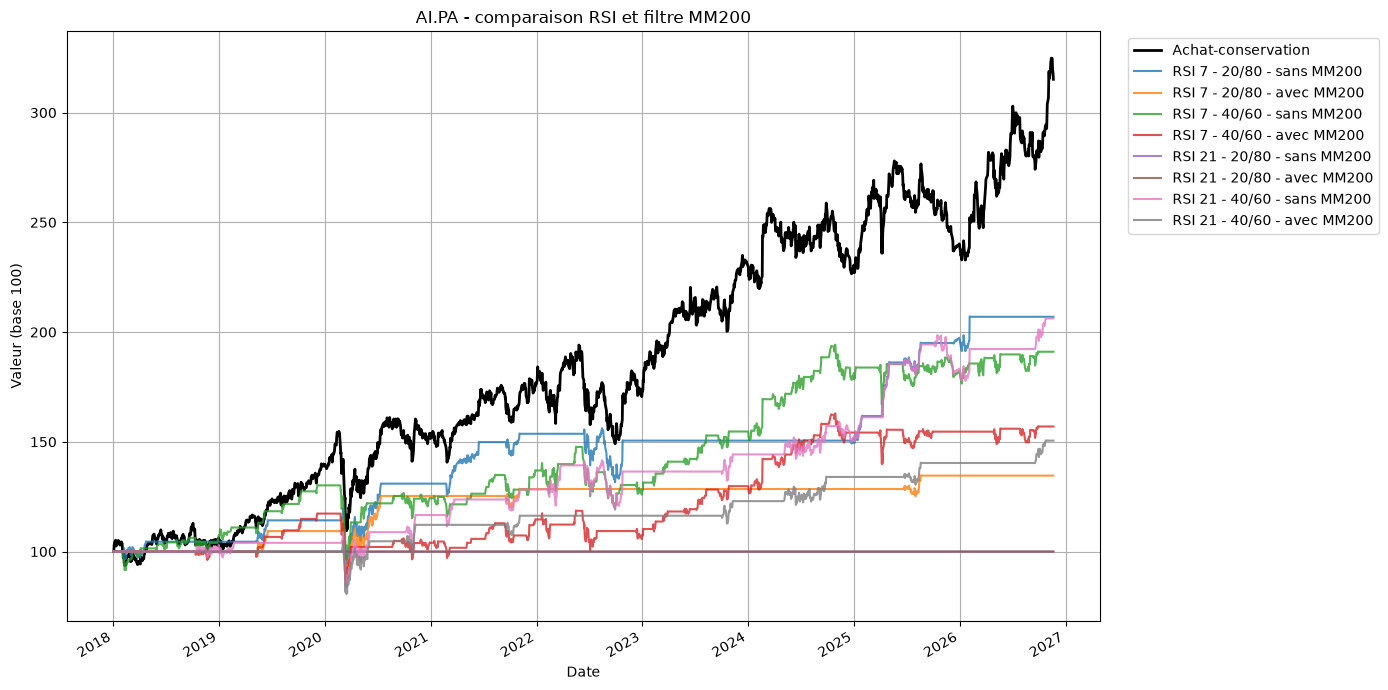

In [3]:
import matplotlib.pyplot as plt

benchmark = (1 + cours["Close"].pct_change().fillna(0)).cumprod() * 100
ax = benchmark.plot(figsize=(14, 7), color="black", linewidth=2, label="Achat-conservation")
for nom, donnees in resultats.items():
    ((1 + donnees["strategie"]).cumprod() * 100).plot(ax=ax, label=nom, alpha=0.8)
ax.set_title(f"{TICKER} - comparaison RSI et filtre MM200")
ax.set_ylabel("Valeur (base 100)")
ax.grid(True)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

Le RSI utilise le lissage de Wilder. Un achat est declenche en zone de survente, une vente en zone de surachat. Le filtre MM200 s'applique aux nouvelles entrees. Les positions sont decalees d'une seance, les couts de transaction sont deduits et la strategie ne prend pas de position vendeuse a decouvert. Le tableau inclut le nombre d'entrees en position et le benchmark achat-conservation ; zero entree signifie que la configuration n'a pas declenche de transaction pendant la periode.